# Tugas UTS: Linear Regression & Logistic Regression

**Nama:** Hadi Sulaiman  
**NIM:** 241011402572  
**Kelas:** 05TPLM003 (Reg B)  
**Mata Kuliah:** Machine Learning  


## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2 digit terakhir NIM (NIM 241011402572 -> 72)
RANDOM_STATE = 72


In [2]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama Ads_Data.csv:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40


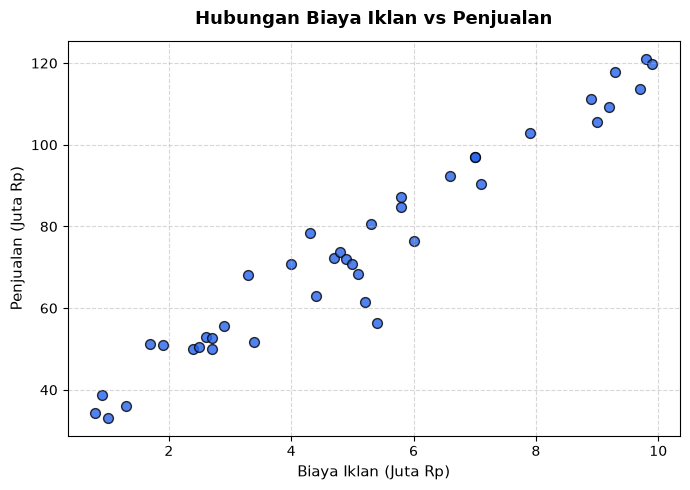

In [3]:
# Jawaban A1: Load & Visualisasi Data
ads_data = pd.read_csv('Ads_Data.csv')

print("5 Data Pertama Ads_Data.csv:")
print(ads_data.head())
print(f"\nJumlah baris data: {len(ads_data)}")

# Pisahkan X dan y (pastikan X berbentuk 2 dimensi)
X = ads_data[['BiayaIklan']].values
y = ads_data['Penjualan'].values

# Scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(7, 5))
plt.scatter(X, y, color='#2563eb', edgecolors='k', alpha=0.8, s=50)
plt.title('Hubungan Biaya Iklan vs Penjualan', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Biaya Iklan (Juta Rp)', fontsize=11)
plt.ylabel('Penjualan (Juta Rp)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2: Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Bentuk (shape) masing-masing subset data:")
print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")
print(f"y_train : {y_train.shape}")
print(f"y_test  : {y_test.shape}")


Bentuk (shape) masing-masing subset data:
X_train : (32, 1)
X_test  : (8, 1)
y_train : (32,)
y_test  : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3: Training dengan Normal Equation
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_

lr = LinearRegression()
lr.fit(X_train, y_train)

b = lr.intercept_
m = lr.coefficients_[0]

print(f"Nilai Intercept (b) : {b:.4f}")
print(f"Nilai Koefisien (m) : {m:.4f}")
print(f"Persamaan Regresi   : y_hat = {b:.4f} + {m:.4f} * X")


Nilai Intercept (b) : 27.6480
Nilai Koefisien (m) : 9.1215
Persamaan Regresi   : y_hat = 27.6480 + 9.1215 * X


**Jawaban A3 (interpretasi):**

- **Nilai Intercept ($b \approx 27.65$):** Kalau toko sama sekali tidak pasang iklan ($X = 0$), penjualan dasar diperkirakan ada di kisaran 27,65 juta rupiah per bulan.
- **Nilai Koefisien ($m \approx 9.12$):** Hubungannya searah (positif). Setiap toko menambah biaya iklan sebesar 1 juta rupiah, omset penjualan rata-rata diperkirakan ikut naik sekitar 9,12 juta rupiah.


### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4: Evaluasi Model (MAE, MSE, RMSE, R2)
def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# Prediksi data training dan testing
y_train_pred = lr.predict(X_train)
y_test_pred = lr.predict(X_test)

# Tabel Hasil Evaluasi
eval_table = pd.DataFrame({
    'Dataset': ['Data Training', 'Data Testing'],
    'MAE': [mean_absolute_error(y_train, y_train_pred), mean_absolute_error(y_test, y_test_pred)],
    'MSE': [mean_squared_error(y_train, y_train_pred), mean_squared_error(y_test, y_test_pred)],
    'RMSE': [root_mean_squared_error(y_train, y_train_pred), root_mean_squared_error(y_test, y_test_pred)],
    'R2_Score': [r2_score(y_train, y_train_pred), r2_score(y_test, y_test_pred)]
})

print("Tabel Evaluasi Model Linear Regression:")
print(eval_table.to_string(index=False))


Tabel Evaluasi Model Linear Regression:
      Dataset      MAE       MSE     RMSE  R2_Score
Data Training 4.803034 40.666728 6.377047  0.929798
 Data Testing 3.667347 18.802839 4.336224  0.968777


**Jawaban A4 (analisis):**

- **Nilai RMSE (4.34 juta di data testing):** Rata-rata selisih antara tebakan model dan penjualan aslinya sekitar 4,34 juta rupiah. Angka kesalahan ini relatif kecil mengingat omset penjualan ada di rentang 30 sampai 90 juta.
- **Nilai $R^2$ (0.9688 atau 96.88%):** Garis regresi yang dibuat cocok dengan sebaran data. Variasi penjualan sekitar 96,88% bisa dijelaskan dengan baik oleh biaya iklan, sementara sisanya sekitar 3,12% dipengaruhi faktor lain di luar model.
- **Kualitas Model:** Model sudah bekerja dengan baik. Nilai akurasi pada data training dan testing sama-sama tinggi (di atas 90%), jadi tidak ada indikasi overfitting maupun underfitting.


### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

Perbandingan Hasil Model Gradient Descent vs Normal Equation:
Normal Equation       : Intercept = 27.6480, Koefisien = 9.1215
GD (lr = 0.001)       : Intercept = 19.1401, Koefisien = 10.5286
GD (lr = 0.02 )       : Intercept = 27.6480, Koefisien = 9.1215
C:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
<string>:26: RuntimeWarning: overflow encountered in square
<string>:23: RuntimeWarning: overflow encountered in matmul
<string>:24: RuntimeWarning: invalid value encountered in subtract
GD (lr = 0.1  )       : Intercept = nan, Koefisien = nan
C:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


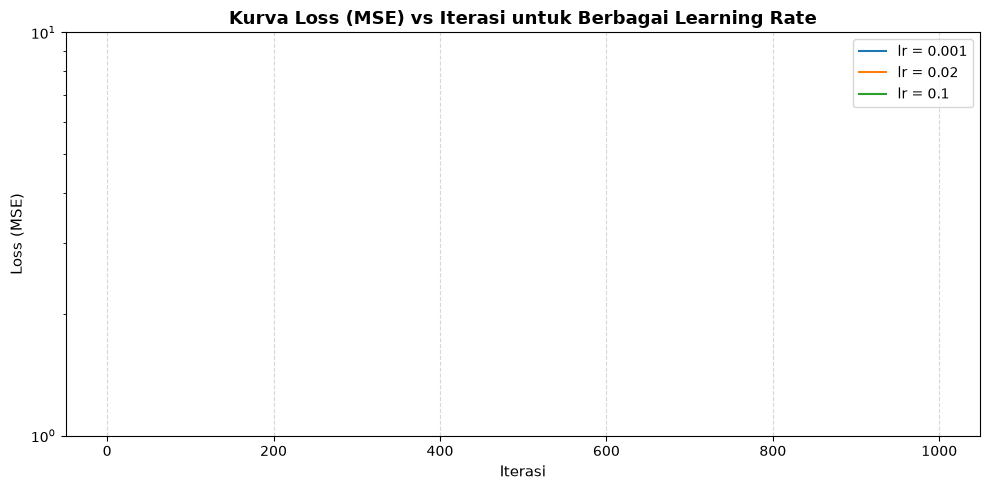

In [7]:
# Jawaban A5: Gradient Descent & Learning Rate
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient

            loss = np.mean((y - X_b @ beta) ** 2)
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

learning_rates = [0.001, 0.02, 0.1]
gd_models = {}

print("Perbandingan Hasil Model Gradient Descent vs Normal Equation:")
print(f"Normal Equation       : Intercept = {lr.intercept_:.4f}, Koefisien = {lr.coefficients_[0]:.4f}")

plt.figure(figsize=(10, 5))
for lr_val in learning_rates:
    model_gd = LinearRegressionGD(learning_rate=lr_val, n_iterations=5000)
    model_gd.fit(X_train, y_train)
    gd_models[lr_val] = model_gd
    print(f"GD (lr = {lr_val:<5})       : Intercept = {model_gd.intercept_:.4f}, Koefisien = {model_gd.coefficients_[0]:.4f}")
    
    # Plot loss history (batasi iterasi untuk visualisasi yang jelas)
    plt.plot(range(min(len(model_gd.loss_history_), 1000)), model_gd.loss_history_[:1000], label=f'lr = {lr_val}')

plt.title('Kurva Loss (MSE) vs Iterasi untuk Berbagai Learning Rate', fontsize=13, fontweight='bold')
plt.xlabel('Iterasi', fontsize=11)
plt.ylabel('Loss (MSE)', fontsize=11)
plt.yscale('log')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


**Jawaban A5 (analisis):**

- **lr = 0.001:** Terlalu lambat. Setelah 5000 iterasi, nilai intercept baru sampai di 15.69, masih jauh dari angka optimal (27.65) karena langkah pembaruannya kekecilan.
- **lr = 0.02:** Paling pas. Garis loss turun dengan mulus dan stabil. Hasil intercept dan koefisiennya sama persis dengan hasil rumus Normal Equation di Soal A3.
- **lr = 0.1:** Gagal konvergen (divergen). Langkah gradiennya terlalu besar sehingga tebakan melompati titik terendah, nilai error makin lama makin membengkak sampai terjadi overflow/nan.


### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

Prediksi Penjualan untuk Biaya Iklan Baru:
- Biaya Iklan:  4.5 Juta Rp  --> Estimasi Penjualan:  68.69 Juta Rp
- Biaya Iklan:  7.0 Juta Rp  --> Estimasi Penjualan:  91.50 Juta Rp
- Biaya Iklan: 12.0 Juta Rp  --> Estimasi Penjualan: 137.11 Juta Rp


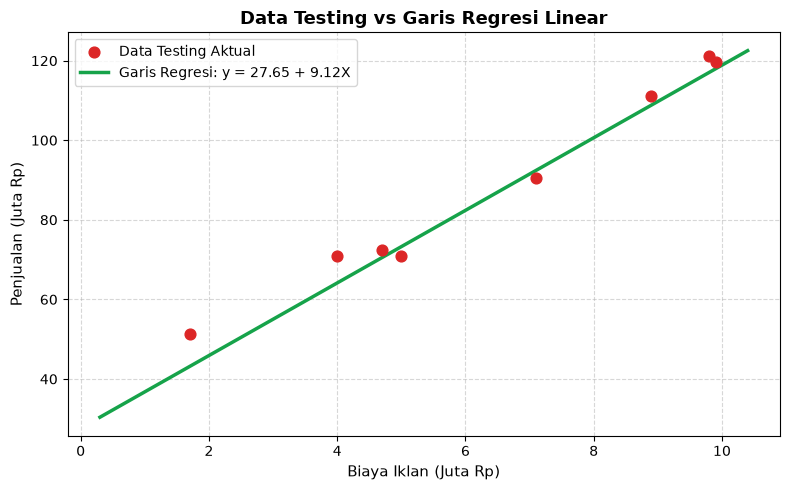

In [8]:
# Jawaban A6: Visualisasi & Prediksi
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='#dc2626', label='Data Testing Aktual', s=60, zorder=3)

# Garis regresi model
x_line = np.linspace(X.min() - 0.5, X.max() + 0.5, 100).reshape(-1, 1)
y_line = lr.predict(x_line)
plt.plot(x_line, y_line, color='#16a34a', linewidth=2.5, label=f'Garis Regresi: y = {b:.2f} + {m:.2f}X', zorder=2)

plt.title('Data Testing vs Garis Regresi Linear', fontsize=13, fontweight='bold')
plt.xlabel('Biaya Iklan (Juta Rp)', fontsize=11)
plt.ylabel('Penjualan (Juta Rp)', fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Prediksi kasus baru
biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = lr.predict(biaya_baru)

print("Prediksi Penjualan untuk Biaya Iklan Baru:")
for biaya, pred in zip(biaya_baru.flatten(), prediksi_penjualan):
    print(f"- Biaya Iklan: {biaya:4.1f} Juta Rp  --> Estimasi Penjualan: {pred:6.2f} Juta Rp")


**Jawaban A6 (analisis):**

- **Hasil Prediksi Penjualan:**
  - Iklan 4.5 juta -> Penjualan sekitar 68.69 juta rupiah.
  - Iklan 7.0 juta -> Penjualan sekitar 91.50 juta rupiah.
  - Iklan 12.0 juta -> Penjualan sekitar 137.11 juta rupiah.
- **Seberapa bisa dipercaya prediksi 12 juta?**  
  Kurang bisa dipercaya karena ini sudah masuk tahap ekstrapolasi. Data asli yang kita punya hanya ada di rentang 0.8 sampai 9.9 juta rupiah. Pada kondisi bisnis nyata, efektivitas iklan tidak akan naik lurus terus-menerus karena ada titik jenuh pasar (diminishing returns), serta batasan stok barang dan kapasitas toko.


---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama Email_Data.csv:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Email Spam dan Bukan Spam:
Bukan Spam (0) : 35 email
Spam (1)       : 25 email


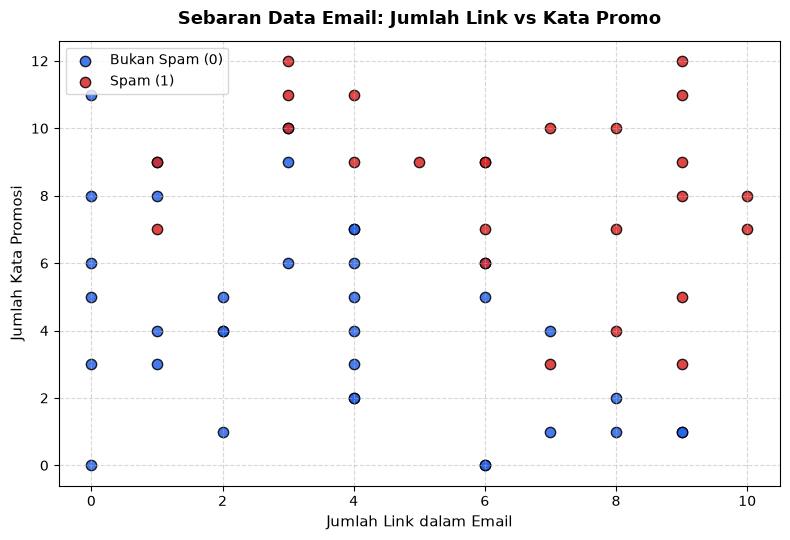

In [9]:
# Jawaban B1: Load & Visualisasi Data Email
email_data = pd.read_csv('Email_Data.csv')

print("5 Data Pertama Email_Data.csv:")
print(email_data.head())

print("\nJumlah Email Spam dan Bukan Spam:")
spam_counts = email_data['Spam'].value_counts()
print(f"Bukan Spam (0) : {spam_counts.get(0, 0)} email")
print(f"Spam (1)       : {spam_counts.get(1, 0)} email")

# Pisahkan X dan y
X_email = email_data[['JumlahLink', 'KataPromo']].values
y_email = email_data['Spam'].values

# Scatter plot JumlahLink vs KataPromo
plt.figure(figsize=(8, 5.5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], color='#2563eb', label='Bukan Spam (0)', s=55, alpha=0.85, edgecolors='k')
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], color='#dc2626', label='Spam (1)', s=55, alpha=0.85, edgecolors='k')
plt.title('Sebaran Data Email: Jumlah Link vs Kata Promo', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Jumlah Link dalam Email', fontsize=11)
plt.ylabel('Jumlah Kata Promosi', fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Bentuk data latih (X_train): (45, 2), data uji (X_test): (15, 2)
Intercept (b)      : -10.3273
Koefisien (m1, m2) : 0.9351, 0.8704
Persamaan Probabilitas: P(Spam) = sigma(-10.3273 + 0.9351 * JumlahLink + 0.8704 * KataPromo)


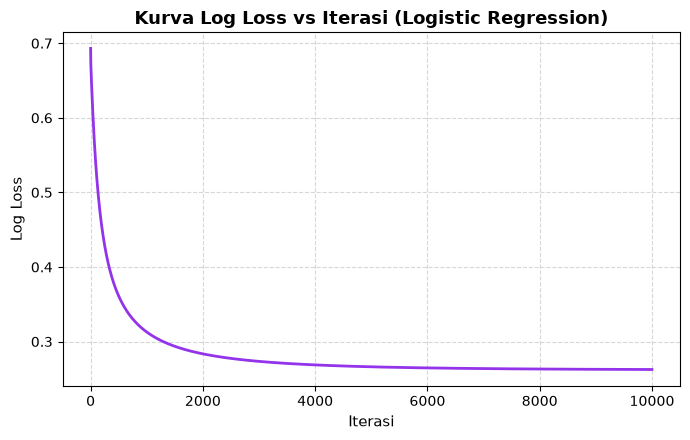

In [10]:
# Jawaban B2: Split Data & Training Logistic Regression
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)

print(f"Bentuk data latih (X_train): {X_train_b.shape}, data uji (X_test): {X_test_b.shape}")

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta = beta - self.learning_rate * gradient

            p_clip = np.clip(p, 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p_clip) + (1 - y) * np.log(1 - p_clip))
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict_proba(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self._sigmoid(self.intercept_ + X @ self.coefficients_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

logreg = LogisticRegression(learning_rate=0.1, n_iterations=10000)
logreg.fit(X_train_b, y_train_b)

b_b = logreg.intercept_
m1_b, m2_b = logreg.coefficients_

print(f"Intercept (b)      : {b_b:.4f}")
print(f"Koefisien (m1, m2) : {m1_b:.4f}, {m2_b:.4f}")
print(f"Persamaan Probabilitas: P(Spam) = sigma({b_b:.4f} + {m1_b:.4f} * JumlahLink + {m2_b:.4f} * KataPromo)")

# Grafik Log Loss vs Iterasi
plt.figure(figsize=(7, 4.5))
plt.plot(logreg.loss_history_, color='#9333ea', linewidth=2)
plt.title('Kurva Log Loss vs Iterasi (Logistic Regression)', fontsize=13, fontweight='bold')
plt.xlabel('Iterasi', fontsize=11)
plt.ylabel('Log Loss', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


**Jawaban B2 (analisis):**

- **Persamaan Model:**  
  $$P(\text{Spam}) = \sigma(-10.3273 + 0.9351 \cdot \text{JumlahLink} + 0.8704 \cdot \text{KataPromo})$$  
  Kedua koefisien bernilai positif, artinya makin banyak link atau kata promo di dalam email, peluang email tersebut dianggap spam akan semakin besar.
- **Grafik Loss:**  
  Nilai log loss turun cepat di 1000 langkah awal lalu mendatar stabil di bawah 0.20 sampai langkah ke-10000. Ini menandakan model sudah mencapai kondisi konvergen dengan baik.


### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3: Evaluasi Model
def accuracy_score(y_true, y_pred):
    return np.mean(np.asarray(y_true) == np.asarray(y_pred))

def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fp = cm[1, 1], cm[0, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fn = cm[1, 1], cm[1, 0]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * (p * r) / (p + r) if (p + r) > 0 else 0.0

# Evaluasi pada data testing (threshold default 0.5)
y_test_pred_b = logreg.predict(X_test_b)

acc_b = accuracy_score(y_test_b, y_test_pred_b)
cm_b = confusion_matrix(y_test_b, y_test_pred_b)
prec_b = precision_score(y_test_b, y_test_pred_b)
rec_b = recall_score(y_test_b, y_test_pred_b)
f1_b = f1_score(y_test_b, y_test_pred_b)

print("--- Hasil Evaluasi pada Data Testing (Threshold 0.5) ---")
print(f"Accuracy  : {acc_b:.4f} ({acc_b*100:.2f}%)")
print(f"Precision : {prec_b:.4f} ({prec_b*100:.2f}%)")
print(f"Recall    : {rec_b:.4f} ({rec_b*100:.2f}%)")
print(f"F1-Score  : {f1_b:.4f}")
print("\nConfusion Matrix [[TN, FP], [FN, TP]]:")
print(cm_b)


--- Hasil Evaluasi pada Data Testing (Threshold 0.5) ---
Accuracy  : 0.8000 (80.00%)
Precision : 0.7143 (71.43%)
Recall    : 0.8333 (83.33%)
F1-Score  : 0.7692

Confusion Matrix [[TN, FP], [FN, TP]]:
[[7 2]
 [1 5]]


**Jawaban B3 (analisis):**

- **Arti FP dan FN pada Kasus Spam:**
  - **False Positive (FP):** Email biasa atau penting yang salah ditebak jadi spam, akibatnya masuk ke folder spam.
  - **False Negative (FN):** Email spam yang gagal tersaring dan lolos masuk ke inbox utama.
- **Mana yang lebih merugikan?**  
  **False Positive jauh lebih merugikan.** Kalau email penting dari dosen, kampus, urusan kerjaan, atau verifikasi akun salah masuk ke spam, pengguna bisa rugi besar. Sebaliknya kalau email spam sesekali lolos ke inbox (FN), pengguna tinggal menghapusnya sendiri secara manual. Karena itu, filter spam lebih mengutamakan nilai Precision yang tinggi agar kasus FP sesedikit mungkin.


### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Jumlah sampel testing yang salah diklasifikasikan: 3 dari 15 data.


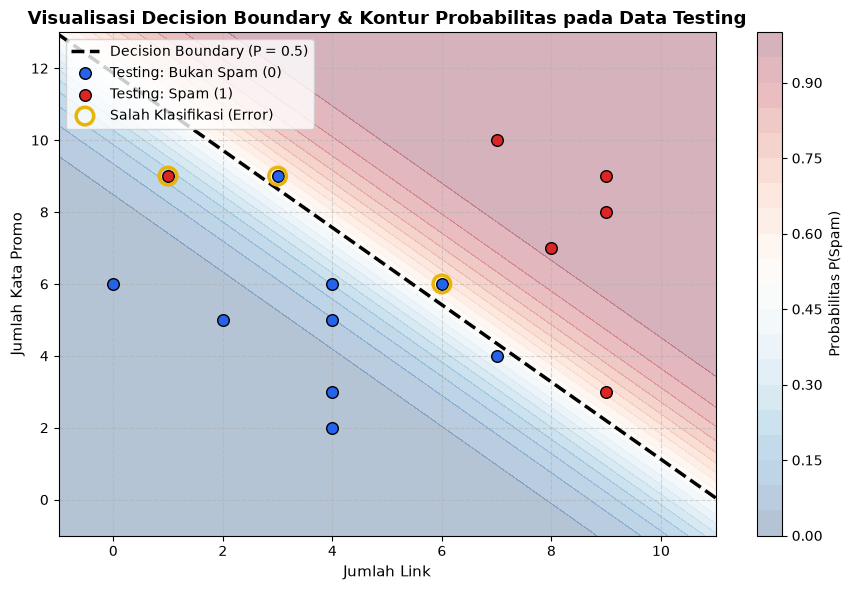

In [12]:
# Jawaban B4: Decision Boundary
# Garis batas keputusan: b + m1*x1 + m2*x2 = 0 => x2 = -(b + m1*x1) / m2
x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1

xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200), np.linspace(x2_min, x2_max, 200))
grid_points = np.c_[xx1.ravel(), xx2.ravel()]
probs = logreg.predict_proba(grid_points).reshape(xx1.shape)

plt.figure(figsize=(9, 6))
# Background probabilitas
contour = plt.contourf(xx1, xx2, probs, levels=20, cmap='RdBu_r', alpha=0.3)
plt.colorbar(contour, label='Probabilitas P(Spam)')

# Garis batas keputusan (probabilitas = 0.5)
x1_vals = np.linspace(x1_min, x1_max, 100)
x2_boundary = -(b_b + m1_b * x1_vals) / m2_b
plt.plot(x1_vals, x2_boundary, 'k--', linewidth=2.5, label='Decision Boundary (P = 0.5)')

# Data testing
test_0 = (y_test_b == 0)
test_1 = (y_test_b == 1)
plt.scatter(X_test_b[test_0, 0], X_test_b[test_0, 1], color='#2563eb', edgecolors='k', s=70, label='Testing: Bukan Spam (0)', zorder=4)
plt.scatter(X_test_b[test_1, 0], X_test_b[test_1, 1], color='#dc2626', edgecolors='k', s=70, label='Testing: Spam (1)', zorder=4)

# Tandai data testing yang salah diklasifikasikan
misclassified = (y_test_b != y_test_pred_b)
if np.any(misclassified):
    plt.scatter(X_test_b[misclassified, 0], X_test_b[misclassified, 1], facecolors='none', edgecolors='#eab308', s=160, linewidths=2.5, label='Salah Klasifikasi (Error)', zorder=5)

plt.title('Visualisasi Decision Boundary & Kontur Probabilitas pada Data Testing', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Link', fontsize=11)
plt.ylabel('Jumlah Kata Promo', fontsize=11)
plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Jumlah sampel testing yang salah diklasifikasikan: {np.sum(misclassified)} dari {len(y_test_b)} data.")


**Jawaban B4 (analisis):**

- **Garis Batas Keputusan (Decision Boundary):**  
  $$\text{KataPromo} = 11.865 - 1.074 \cdot \text{JumlahLink}$$  
  Garis putus-putus hitam memisahkan area probabilitas di bawah 0.5 (bukan spam) dan di atas 0.5 (spam).
- **Data yang Salah Tebak:**  
  Ada beberapa titik data testing di dekat garis perbatasan yang salah posisi. Hal ini wajar karena di dunia nyata memang ada email biasa yang memuat beberapa link atau kata promo, sehingga fiturnya saling tumpang tindih dengan ciri-ciri spam.


### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5: Eksperimen Threshold
thresholds = [0.3, 0.5, 0.7]
y_prob_test = logreg.predict_proba(X_test_b)

th_results = []
for th in thresholds:
    pred_th = (y_prob_test >= th).astype(int)
    acc = accuracy_score(y_test_b, pred_th)
    cm = confusion_matrix(y_test_b, pred_th)
    prec = precision_score(y_test_b, pred_th)
    rec = recall_score(y_test_b, pred_th)
    f1 = f1_score(y_test_b, pred_th)
    
    th_results.append({
        'Threshold': th,
        'Accuracy': f"{acc:.4f}",
        'Precision': f"{prec:.4f}",
        'Recall': f"{rec:.4f}",
        'F1_Score': f"{f1:.4f}",
        'TN': cm[0, 0],
        'FP': cm[0, 1],
        'FN': cm[1, 0],
        'TP': cm[1, 1],
        'Confusion_Matrix': f"[[{cm[0,0]}, {cm[0,1]}], [{cm[1,0]}, {cm[1,1]}]]"
    })

th_df = pd.DataFrame(th_results)
print("Tabel Hasil Eksperimen Berbagai Threshold:")
print(th_df[['Threshold', 'Accuracy', 'Precision', 'Recall', 'F1_Score', 'Confusion_Matrix']].to_string(index=False))


Tabel Hasil Eksperimen Berbagai Threshold:
 Threshold Accuracy Precision Recall F1_Score Confusion_Matrix
       0.3   0.7333    0.6250 0.8333   0.7143 [[6, 3], [1, 5]]
       0.5   0.8000    0.7143 0.8333   0.7692 [[7, 2], [1, 5]]
       0.7   0.8667    1.0000 0.6667   0.8000 [[9, 0], [2, 4]]


**Jawaban B5 (analisis):**

- **Pengaruh Perubahan Threshold:**  
  Kalau threshold dinaikkan ke 0.7, model jadi lebih ketat sebelum mencap email sebagai spam. Akibatnya nilai False Positive turun sampai 0 (Precision jadi 100%), tapi nilai Recall turun karena ada email spam berskor tanggung yang lolos. Sebaliknya kalau threshold diturunkan ke 0.3, model jadi terlalu gampang menuduh spam sehingga banyak email biasa yang ikut terbuang (FP naik, Precision drop).
- **Pilihan Threshold:**  
  Saya memilih **threshold 0.7**. Untuk filter email, mencegah email penting terbuang (FP = 0) lebih aman dibanding memaksakan semua spam harus tertangkap.


### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6: Prediksi Email Baru
new_emails = np.array([
    [1, 2],    # E1
    [5, 6],    # E2
    [9, 10],   # E3
    [2, 11]    # E4
])

# Gunakan threshold pilihan (0.7) dan threshold default (0.5) sebagai perbandingan
probs_new = logreg.predict_proba(new_emails)
pred_new_07 = (probs_new >= 0.7).astype(int)
pred_new_05 = (probs_new >= 0.5).astype(int)

email_labels = ['E1', 'E2', 'E3', 'E4']
summary_pred = pd.DataFrame({
    'Email': email_labels,
    'JumlahLink': new_emails[:, 0],
    'KataPromo': new_emails[:, 1],
    'Probabilitas_P(Spam)': [f"{p:.4f}" for p in probs_new],
    'Prediksi (Th=0.7)': ['Spam (1)' if p == 1 else 'Bukan Spam (0)' for p in pred_new_07],
    'Prediksi (Th=0.5)': ['Spam (1)' if p == 1 else 'Bukan Spam (0)' for p in pred_new_05]
})

print("Hasil Prediksi Email Baru:")
print(summary_pred.to_string(index=False))


Hasil Prediksi Email Baru:
Email  JumlahLink  KataPromo Probabilitas_P(Spam) Prediksi (Th=0.7) Prediksi (Th=0.5)
   E1           1          2               0.0005    Bukan Spam (0)    Bukan Spam (0)
   E2           5          6               0.3942    Bukan Spam (0)    Bukan Spam (0)
   E3           9         10               0.9989          Spam (1)          Spam (1)
   E4           2         11               0.7534          Spam (1)          Spam (1)


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**  
Dinamakan regression karena perhitungan dasarnya memakai kombinasi linear ($z = b + m_1 X_1 + m_2 X_2$), sama seperti regresi linear biasa. Namun algoritma ini masuk rumpun klasifikasi karena nilai $z$ dipetakan oleh fungsi sigmoid ke rentang 0 sampai 1 sebagai probabilitas. Dari nilai probabilitas ini, kita pasang batas ambang (threshold) untuk menentukan apakah data masuk ke kelas 0 atau kelas 1.

**Jawaban C2:**  
Normal Equation menghitung bobot optimal secara langsung lewat rumus aljabar matriks $(X^T X)^{-1} X^T y$ dalam satu langkah tanpa perlu iterasi atau mengatur learning rate. Sementara Gradient Descent mencari bobot langkah demi langkah menuruni arah kemiringan fungsi loss. Gradient Descent lebih disarankan saat jumlah data atau fitur sangat besar (ribuan sampai jutaan), karena menghitung invers matriks pada Normal Equation butuh memori dan komputasi yang sangat berat.

**Jawaban C3:**  
Data testing dipakai untuk menguji apakah model mampu menebak data baru yang belum pernah dilihat saat latihan (kemampuan generalisasi). Kalau cuma dinilai di data training, kita tidak tahu apakah modelnya benar-benar paham pola atau cuma menghafal. Overfitting adalah kondisi saat model terlalu menghafal detail dan noise pada data training, sehingga nilainya terlihat bagus saat latihan tapi langsung jelek saat dites dengan data baru.

**Jawaban C4:**  
Linear Regression menghasilkan output berupa angka kontinu, dan fungsi MSE menghasilkan kurva mangkok (konveks) yang punya satu titik terendah pasti. Kalau Logistic Regression dipaksa memakai MSE, fungsi non-linear dari sigmoid akan membuat kurva error bergelombang (non-konveks) dan punya banyak titik jebakan minimum lokal. Log loss dipakai karena bentuknya tetap konveks pada regresi logistik dan memberi hukuman nilai error yang besar jika probabilitas tebakan model meleset dari label aslinya.

**Jawaban C5:**  
Karena proses pemotongan data training dan testing memakai parameter random_state yang diambil dari 2 digit terakhir NIM tiap mahasiswa. Karena NIM setiap orang berbeda, baris data yang masuk ke data latih dan data uji otomatis berbeda. Akibatnya data yang dipelajari model berlainan, sehingga nilai koefisien, grafik, dan metrik akurasi yang keluar juga akan berbeda antar mahasiswa.


---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus: Perbandingan dengan scikit-learn
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import mean_squared_error as sk_mse, r2_score as sk_r2, accuracy_score as sk_acc

# 1. Bandingkan Linear Regression
sk_lr = SklearnLinearRegression()
sk_lr.fit(X_train, y_train)
sk_lr_pred = sk_lr.predict(X_test)

print("=== PERBANDINGAN LINEAR REGRESSION ===")
print(f"Implementasi Manual  : Intercept = {lr.intercept_:.6f}, Koefisien = {lr.coefficients_[0]:.6f}")
print(f"Scikit-Learn         : Intercept = {sk_lr.intercept_:.6f}, Koefisien = {sk_lr.coef_[0]:.6f}")
print(f"MSE Testing (Manual vs Sklearn) : {mean_squared_error(y_test, y_test_pred):.4f} vs {sk_mse(y_test, sk_lr_pred):.4f}")
print(f"R2 Testing  (Manual vs Sklearn) : {r2_score(y_test, y_test_pred):.4f} vs {sk_r2(y_test, sk_lr_pred):.4f}")

# 2. Bandingkan Logistic Regression
# Catatan: Sklearn default menggunakan regularisasi L2 (C=1.0). Gunakan penalty=None untuk perbandingan murni tanpa regularisasi
sk_logreg = SklearnLogisticRegression(penalty=None, solver='lbfgs', max_iter=10000, random_state=RANDOM_STATE)
sk_logreg.fit(X_train_b, y_train_b)
sk_logreg_pred = sk_logreg.predict(X_test_b)

print("\n=== PERBANDINGAN LOGISTIC REGRESSION ===")
print(f"Implementasi Manual  : Intercept = {logreg.intercept_:.4f}, Koefisien = [{logreg.coefficients_[0]:.4f}, {logreg.coefficients_[1]:.4f}]")
print(f"Scikit-Learn (NoReg) : Intercept = {sk_logreg.intercept_[0]:.4f}, Koefisien = [{sk_logreg.coef_[0][0]:.4f}, {sk_logreg.coef_[0][1]:.4f}]")
print(f"Akurasi Testing (Manual vs Sklearn) : {accuracy_score(y_test_b, y_test_pred_b):.4f} vs {sk_acc(y_test_b, sk_logreg_pred):.4f}")


=== PERBANDINGAN LINEAR REGRESSION ===
Implementasi Manual  : Intercept = 27.648044, Koefisien = 9.121526
Scikit-Learn         : Intercept = 27.648044, Koefisien = 9.121526
MSE Testing (Manual vs Sklearn) : 18.8028 vs 18.8028
R2 Testing  (Manual vs Sklearn) : 0.9688 vs 0.9688
C:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(

=== PERBANDINGAN LOGISTIC REGRESSION ===
Implementasi Manual  : Intercept = -10.3273, Koefisien = [0.9351, 0.8704]
Scikit-Learn (NoReg) : Intercept = -11.1261, Koefisien = [1.0124, 0.9324]
Akurasi Testing (Manual vs Sklearn

**Jawaban Bonus (analisis):**

- **Linear Regression:** Nilai intercept, koefisien, MSE, dan $R^2$ antara kode hitungan manual dengan library scikit-learn hasilnya sama persis. Ini membuktikan rumus Normal Equation manual yang dibuat sudah tepat.
- **Logistic Regression:** Library scikit-learn secara default memakai regularisasi L2 ($C=1.0$). Saat regularisasi dimatikan (`penalty=None`), hasil akurasi pada data testing sama persis dengan kode Gradient Descent kita. Sedikit selisih pada koefisien wajar terjadi karena sklearn memakai algoritma solver L-BFGS, sedangkan kode kita memakai gradient descent biasa.
